### Libraries

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV, RidgeCV, LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

### Load Data

In [12]:
# Case 1
df_train1 = pd.read_csv('../data/case1/train1.csv')
df_test1 = pd.read_csv('../data/case1/test1.csv')

In [13]:
# # change to binary 
# mapping = {
#     "stable": 0,
#     "transient": 1
# }
# df_train1['operating_state'] = df_train1['operating_state'].map(mapping)

# # speed in krpm, n
# df_train1['krpm'] = df_train1['speed_rpm'] / 1000

# # pressure rise across pump
# df_train1['delta_P'] = (
#     df_train1['outlet_pressure_bar']
#     - df_train1['inlet_pressure_bar']
# )

## TASK 0
### Subtask 1
#### Create relevant new feature columns by combining existing features.

In [14]:
### new features

for df in [df_train1, df_test1]:
    # change to binary 
    mapping = {
        "stable": 0,
        "transient": 1
    }
    df['operating_state'] = df['operating_state'].map(mapping)

    # speed in krpm, n
    df['krpm'] = df['speed_rpm'] / 1000

    # pressure rise across pump
    df['delta_P'] = (
        df['outlet_pressure_bar']
        - df['inlet_pressure_bar']
    )

    df['n2'] = df['krpm']**2
    df['n3'] = df['krpm']**3

    df['Q2'] = df['flow_m3_h']**2
    df['Q3'] = df['flow_m3_h']**3

    df['nQ'] = df['krpm'] * df['flow_m3_h']
    df['nQ2'] = df['krpm'] * df['flow_m3_h']**2
    df['nQ3'] = df['krpm'] * df['Q3']

    df['n2Q'] = df['krpm']**2 * df['flow_m3_h']
    df['n2Q2'] = df['n2'] * df['Q2']
    df['n2Q3'] = df['n2'] * df['Q3']

    df['n3Q'] = df['flow_m3_h'] * df['n3']
    df['n3Q2'] = df['n3'] * df['Q2']
    df['n3Q3'] = df['n3'] * df['Q3']



In [15]:
df_train1

,pump_id,elapsed_s,operating_state,speed_rpm,power_w,inlet_pressure_bar,outlet_pressure_bar,flow_m3_h,krpm,delta_P,...,Q3,nQ,nQ2,nQ3,n2Q,n2Q2,n2Q3,n3Q,n3Q2,n3Q3
0,99223468_model_01,14.5,0,4230.396017,669.992714,1.057136,2.414427,0.652884,4.230396,1.357291,...,0.278296,2.761956,1.803236,1.177303,11.684169,7.628402,4.980459e+00,49.428660,32.271162,2.106931e+01
1,99223468_model_01,24.5,0,3796.519900,931.528480,2.097392,2.390436,43.040564,3.796520,0.293043,...,79732.222413,163.404359,7033.015810,302704.969059,620.367900,26700.984478,1.149225e+06,2355.239078,101370.818919,4.363057e+06
2,99223468_model_01,34.5,0,3508.264375,724.198083,2.247896,2.433662,40.939560,3.508264,0.185766,...,68616.648822,143.626799,5880.017914,240725.344589,503.880782,20628.657370,8.445282e+05,1767.746997,72370.783753,2.962828e+06
3,99223468_model_01,44.5,0,1498.405243,99.463217,2.287246,2.451128,11.857951,1.498405,0.163881,...,1667.358317,17.768016,210.692258,2498.378443,26.623688,315.702384,3.743583e+03,39.893074,473.050107,5.609405e+03
4,99223468_model_01,64.5,0,3224.873653,608.195308,2.464618,2.696299,36.000996,3.224874,0.231682,...,46659.871276,116.098662,4179.667444,150472.189541,374.403518,13478.899418,4.852538e+05,1207.404040,43467.747606,1.564882e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,99223468_model_01,5944.5,0,4376.002303,815.229829,1.016499,2.478924,3.032111,4.376002,1.462426,...,27.876314,13.268525,40.231643,121.986814,58.063097,176.053764,5.338146e+02,254.084248,770.411677,2.335974e+03
476,99223468_model_01,5964.5,0,3514.587072,515.961500,1.411002,2.338274,5.566221,3.514587,0.927272,...,172.457177,19.562967,108.891795,606.115765,68.755752,382.709694,2.130247e+03,241.648078,1345.066544,7.486937e+03
477,99223468_model_01,5974.5,0,2935.129740,534.173942,2.178489,2.678476,22.873572,2.935130,0.499988,...,11967.459519,67.136901,1535.660738,35126.046346,197.055515,4507.363504,1.030995e+05,578.383504,13229.696669,3.026104e+05
478,99223468_model_01,5984.5,0,2214.152995,154.677482,2.032066,2.410823,3.776250,2.214153,0.378757,...,53.849573,8.361196,31.573966,119.231193,18.512966,69.909591,2.639961e+02,40.990539,154.790530,5.845278e+02


##### Defining X and y

In [16]:
exclude_cols = [
    'pump_id',
    'speed_rpm',
    'elapsed_s',
    'operating_state',
    'power_w',
    'inlet_pressure_bar',
    'outlet_pressure_bar',
    'delta_P'
]

X = df_train1.drop(columns=exclude_cols)
y = df_train1['power_w']

# split into train and validation set
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)


In [17]:
X_train

,flow_m3_h,krpm,n2,n3,Q2,Q3,nQ,nQ2,nQ3,n2Q,n2Q2,n2Q3,n3Q,n3Q2,n3Q3
132,27.622538,3.507151,12.300109,43.138340,763.004610,21076.123888,96.876414,2675.972443,73917.150694,339.760221,9385.039648,259238.615025,1191.590427,32914.751954,9.091890e+05
228,13.954229,3.791468,14.375231,54.503228,194.720519,2717.174795,52.907016,738.276641,10302.081622,200.595265,2799.152350,39060.014085,760.550553,10612.896909,1.480948e+05
473,13.503574,2.646155,7.002136,18.528738,182.346500,2462.329389,35.732549,482.517100,6515.705180,94.553861,1276.815028,17241.565722,250.204172,3378.650448,4.562386e+04
42,11.316769,4.358652,18.997844,82.804987,128.069270,1449.330390,49.325856,558.209337,6317.126344,214.994225,2433.040067,27534.153365,937.084941,10604.774178,1.200118e+05
360,19.453809,2.498750,6.243754,15.601582,378.450675,7362.307043,48.610213,945.653778,18396.567729,121.464788,2362.952763,45968.431123,303.510190,5904.429181,1.148636e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
106,30.296619,3.653348,13.346949,48.761047,917.885139,27808.816606,110.684084,3353.353565,101595.276245,404.367445,12250.966540,371162.869012,1477.294878,44757.040459,1.355987e+06
270,7.717200,2.935271,8.615817,25.289760,59.555172,459.599163,22.652074,174.810584,1349.048201,66.489983,513.116479,3959.822375,195.166133,1506.136038,1.162315e+04
348,14.777742,2.935730,8.618508,25.301608,218.381673,3227.188128,43.383455,641.109528,9474.151514,127.362091,1882.124179,27813.546450,373.900652,5525.407548,8.165305e+04
435,13.152133,2.217826,4.918752,10.908935,172.978607,2275.037682,29.169142,383.636435,5045.637492,64.692078,850.838822,11190.345507,143.475765,1887.012375,2.481824e+04


### Subtask 2
#### Fit Linear Regression models with relevant new and old feature columns.

In [18]:
model_0 = LinearRegression()
model_0.fit(X_train, y_train)
y_0_pred = model_0.predict(X_val)


r2_model_0 = round(model_0.score(X_val, y_val) , 5)
print(f"R^2 for model 0 is {r2_model_0}")

mse_model_0 = round(mean_squared_error(y_true = y_val, y_pred = y_0_pred) , 5)
print(f"MSE for model 0 is {mse_model_0}")

R^2 for model 0 is 0.99959
MSE for model 0 is 135.89109


### Subtask 3
#### Apply feature selection method to find polynomial of form $P$ that matches the data best.
##### Lasso

In [19]:
# use lasso as features selection method

lasso_0 = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', LassoCV(
        cv=5,
        max_iter=2000,
        random_state=42
    ))
])

lasso_0.fit(X_train, y_train)
lasso_model = lasso_0.named_steps['lasso']


sel_features_las = X_train.columns[lasso_model.coef_ != 0]
best_alp_las = round(lasso_model.alpha_ , 5)
print(f"The selected features are {sel_features_las} \nBest alpha is {best_alp_las}")

# fit linear regression on selected features
model_0_lasso = LinearRegression()

X_train_lasso = X_train[sel_features_las]
X_val_lasso = X_val[sel_features_las]
model_0_lasso.fit(X_train_lasso, y_train)
y_pred_las = model_0_lasso.predict(X_val_lasso)

# Print coefficients
coef_df = pd.DataFrame({
    'Feature': X_train_lasso.columns,
    'Coefficient': model_0_lasso.coef_
})

print("\nRegression Coefficients:")
print(coef_df)

print(f"\nIntercept: {model_0_lasso.intercept_:.4f}")

equation = f"y = {model_0_lasso.intercept_:.4f}"

for feature, coef in zip(X_train_lasso.columns, model_0_lasso.coef_):
    sign = "+" if coef >= 0 else "-"
    equation += f" {sign} {abs(coef):.4f}*{feature}"

print("\nRegression Equation:")
print(equation)


r2_lasso = round(r2_score(y_val, y_pred_las) , 5)
print(f"R^2 for model 0 using lasso is {r2_lasso}")

mse_lasso = round(mean_squared_error(y_true = y_val, y_pred = y_pred_las) , 5)
print(f"MSE for model 0 using lasso is {mse_lasso}")

The selected features are Index(['n2', 'n3', 'Q3', 'nQ', 'n2Q', 'n2Q3', 'n3Q', 'n3Q3'], dtype='object') 
Best alpha is 0.51822

Regression Coefficients:
  Feature  Coefficient
0      n2     0.962819
1      n3     7.704209
2      Q3    -0.010084
3      nQ    -0.350364
4     n2Q     2.288562
5    n2Q3    -0.000157
6     n3Q    -0.011751
7    n3Q3     0.000025

Intercept: 39.7947

Regression Equation:
y = 39.7947 + 0.9628*n2 + 7.7042*n3 - 0.0101*Q3 - 0.3504*nQ + 2.2886*n2Q - 0.0002*n2Q3 - 0.0118*n3Q + 0.0000*n3Q3
R^2 for model 0 using lasso is 0.99952
MSE for model 0 using lasso is 160.45757


### Subtask 4
#### Report your final regression expression and your test errors, using one or more informative error measures of your choice, and show a plot of errors versus flow.

Final reg: $P = 31.3534 + 1.7682*n^2 + 7.3905*n^3 - 0.1956*Q^2 - 0.0049*Q^3 + 2.3700*nQ + 1.3508*n^2Q - 0.0008*nQ^3 + 0.1110*n^3Q$

##### Lasso

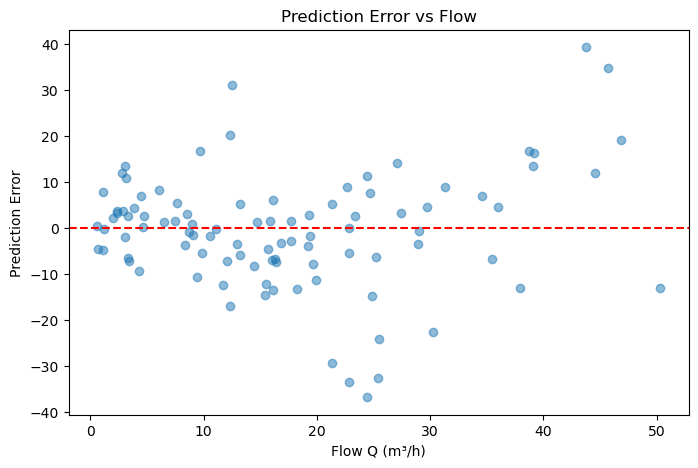

In [20]:
errors = y_pred_las - y_val

plt.figure(figsize=(8,5))
plt.scatter(X_val['flow_m3_h'], errors, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Flow Q (m³/h)')
plt.ylabel('Prediction Error')      # Predicted P - True P)
plt.title('Prediction Error vs Flow')
plt.show()

#### Forward Feature Selection

In [21]:
forward = SequentialFeatureSelector(
    model_0,
    n_features_to_select = 'auto',
    direction = 'forward',
    cv=5
)

forward.fit(X_train, y_train)

selected_features_f = X_train.columns[forward.get_support()]
print(f"The selected features are: {selected_features_f}")

X_train_forward = X_train[selected_features_f]
X_val_forward = X_val[selected_features_f]

model_0_forward = LinearRegression()

model_0_forward.fit(X_train_forward, y_train)

y_pred_forward = model_0_forward.predict(X_val_forward)

r2_forward = round(r2_score(y_val, y_pred_forward) , 5)
print(f"R^2 for model 0 using Forward Elimination is {r2_forward}")

mse_forward = round(mean_squared_error(y_true = y_val, y_pred = y_pred_forward) , 3)
print(f"MSE for model 0 using forward selection is {mse_forward}")

The selected features are: Index(['flow_m3_h', 'krpm', 'n2', 'n3', 'Q3', 'nQ2', 'n2Q'], dtype='object')
R^2 for model 0 using Forward Elimination is 0.99959
MSE for model 0 using forward selection is 134.846


#### Backward Feature Elimination

In [22]:
backward = SequentialFeatureSelector(
    model_0,
    n_features_to_select = 'auto',
    direction = 'backward',
    cv=5
)

backward.fit(X_train, y_train)

selected_features_b = X_train.columns[backward.get_support()]
print(f"The selected features are: {selected_features_b}")

X_train_backward = X_train[selected_features_b]
X_val_backward = X_val[selected_features_b]

model_0_backward = LinearRegression()

model_0_backward.fit(X_train_backward, y_train)

y_pred_backward = model_0_backward.predict(X_val_backward)

r2_backward = round(r2_score(y_val, y_pred_backward) , 5)
print(f"R^2 for model 0 using Backward Elimination is {r2_backward}")

mse_backward = round(mean_squared_error(y_true = y_val, y_pred = y_pred_backward) , 3)
print(f"MSE for model 0 using backward selection is {mse_backward}")

The selected features are: Index(['n3', 'Q2', 'Q3', 'nQ2', 'nQ3', 'n2Q', 'n2Q3', 'n3Q3'], dtype='object')
R^2 for model 0 using Backward Elimination is 0.99959
MSE for model 0 using backward selection is 135.768
